#Model Evaluation and Selection

Quantifying a learning algorithm's performance and comparing different models are some of the common tasks when applying machine learning to real world applications. In this notebook, we will:

* split datasets into training, cross validation, and test sets
* evaluate regression and classification models
* add polynomial features to improve the performance of a linear regression model
* compare several neural network architectures


## Imports and Setup

First, you will import the packages needed for the tasks in this notebook. We also included some commands to make the outputs later more readable by reducing verbosity and suppressing non-critical warnings.

In [2]:

# for array computations and loading data
import numpy as np

# for building linear regression models and preparing data
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

#for building and training neural networks
import tensorflow as tf

#custom functions
import utils

#reduce display precision for numpy arrays to 2 decimal points
np.set_printoptions(precision=2)

#suppress warnings
tf.get_logger().setLevel('ERROR')
tf.autograph.set_verbosity(0)


I0000 00:00:1794556459.717972  195589 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## Regression

First, you will be tasked to develop a model for a regression problem. You are given the dataset below consisting of 50 examples of an input feature `x` and its corresponding target `y`.

In [5]:
#Load the dataset from text file
filepath = 'data/data_w3_ex1.csv'
data = np.loadtxt(filepath, delimiter=',')

# Split the inputs and outputs into separate arrays
x = np.expand_dims(data[:, 0], axis=1)
y = np.expand_dims(data[:, 1], axis=1)

print(f"the shape of the inputs x is: {x.shape}")
print(f"the shape of the targets y is: {y.shape}")

((50, 1), (50, 1))

You can plot the dataset to get an idea of how the target behaves with respect to the input. In case you want to inspect the code, you can find the `plot_dataset()` function in the `utils.py` file outside this notebook.

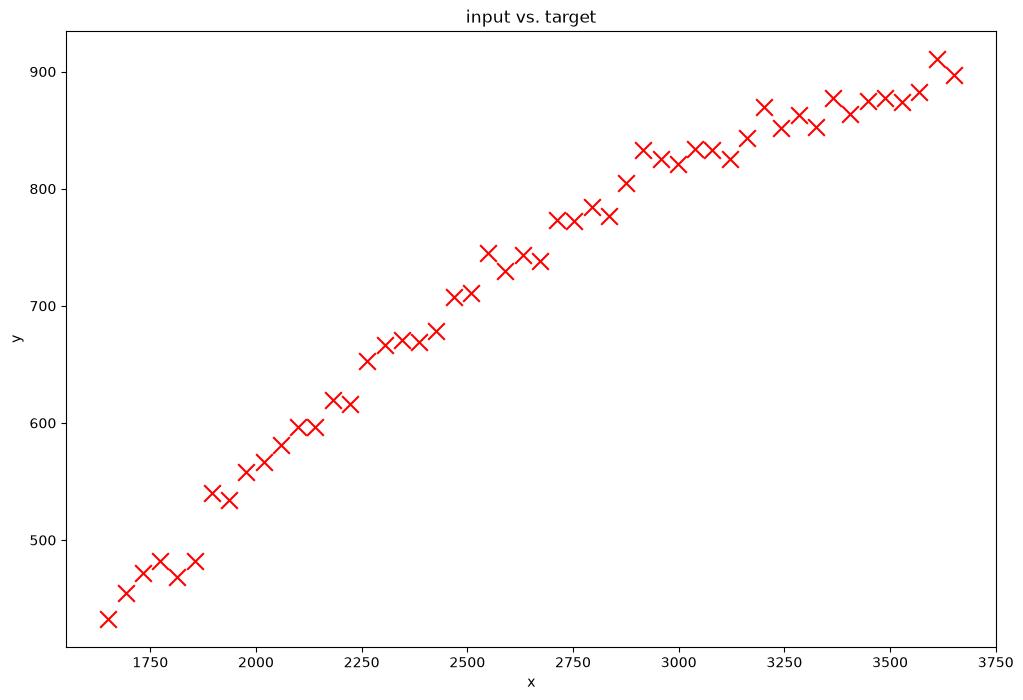

In [6]:
# Plot the entire dataset
utils.plot_dataset(x=x, y=y, title="input vs. target")

## Split the dataset into training, cross validation, and test sets

In previous labs, we used the entire dataset to train your models. In practice however, it is best to hold out a portion of your data to measure how well your model generalizes to new examples. This will let you know if the model has overfit to your training set.

As mentioned in the lecture, it is common to split your data into three parts:

* ***training set*** - used to train the model
* ***cross validation set (also called validation, development, or dev set)*** - used to evaluate the different model configurations you are choosing from. For example, you can use this to make a decision on what polynomial features to add to your dataset.
* ***test set*** - used to give a fair estimate of your chosen model's performance against new examples. This should not be used to make decisions while you are still developing the models.

Scikit-learn provides a [`train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) function to split your data into the parts mentioned above. In the code cell below, you will split the entire dataset into 60% training, 20% cross validation, and 20% test.

In [7]:
# Get 60% of the dataset as the training set and the remaining 40% as the test and development set
x_train, x_, y_train, y_ = train_test_split(x, y, test_size=0.4, random_state=42)

# Split the 40% subset above into two: one half for cross validation and the other for the test set
x_cv, x_test, y_cv, y_test = train_test_split(x_, y_, test_size=0.50, random_state=1)

#delete the temporary variables to free up memory
del x_, y_

print(f"the shape of the training set (input) is: {x_train.shape}")
print(f"the shape of the training set (target) is: {y_train.shape}\n")
print(f"the shape of the cross validation set (input) is: {x_cv.shape}")
print(f"the shape of the cross validation set (target) is: {y_cv.shape}\n")
print(f"the shape of the test set (input) is: {x_test.shape}")
print(f"the shape of the test set (target) is: {y_test.shape}")

the shape of the training set (input) is: (30, 1)
the shape of the training set (target) is: (30, 1)

the shape of the cross validation set (input) is: (10, 1)
the shape of the cross validation set (target) is: (10, 1)

the shape of the test set (input) is: (10, 1)
the shape of the test set (target) is: (10, 1)


You can plot the dataset again below to see which points were used as training, cross validation, or test data.

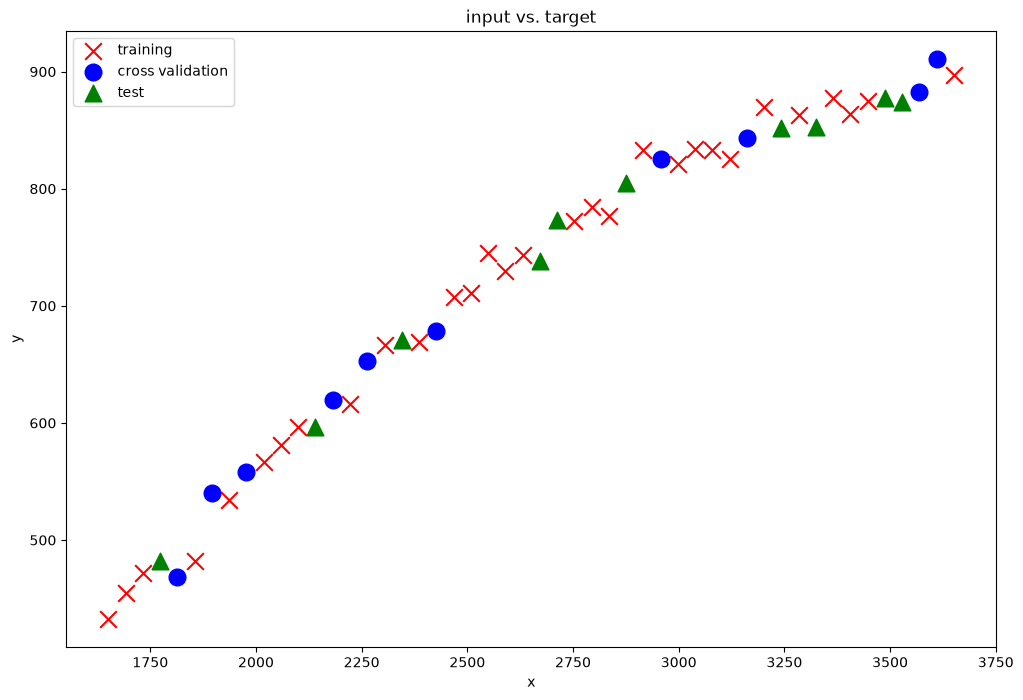

In [8]:
utils.plot_train_cv_test(x_train, y_train, x_cv, y_cv, x_test, y_test, title="input vs. target")

## Fit a linear model

Now that you have split the data, one of the first things you can try is to fit a linear model. You will do that in the next sections below.

### Feature scaling

In the previous course of this specialization, you saw that it is usually a good idea to perform feature scaling to help your model converge faster. This is especially true if your input features have widely different ranges of values. Later in this lab, you will be adding polynomial terms so your input features will indeed have different ranges. For example, $x$ runs from around 1600 to 3600, while $x^2$ will run from 2.56 million to 12.96 million. 

You will only use $x$ for this first model but it's good to practice feature scaling now so you can apply it later. For that, you will use the [`StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) class from scikit-learn. This computes the z-score of your inputs. As a refresher, the z-score is given by the equation:

$$ z = \frac{x - \mu}{\sigma} $$

where $\mu$ is the mean of the feature values and $\sigma$ is the standard deviation. The code below shows how to prepare the training set using the said class. You can plot the results again to inspect if it still follows the same pattern as before. The new graph should have a reduced range of values for `x`.

Computed mean of the training set: 2619.71
Computed standard deviation of the training set: 565.76


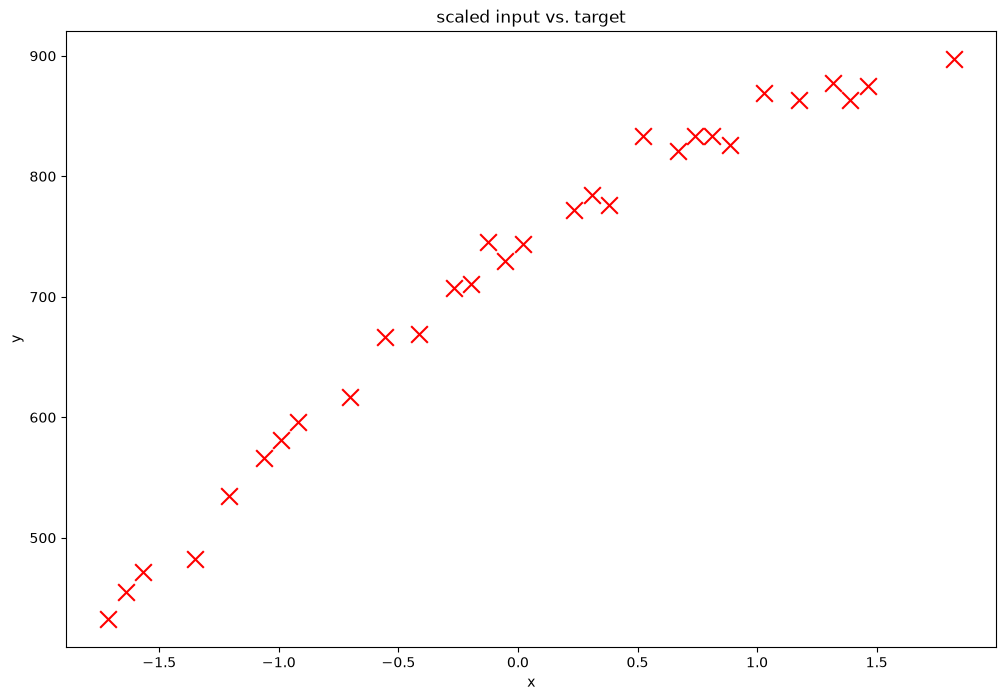

In [15]:
#Initialize the class
scaler_linear = StandardScaler()

#Compute the mean and standard deviation of the training set and then transform it
X_train_scaled = scaler_linear.fit_transform(x_train)

#Check that the mean and standard deviation have been computed
assert scaler_linear.mean_ is not None
assert scaler_linear.scale_ is not None

print(f"Computed mean of the training set: {scaler_linear.mean_.squeeze():.2f}")
print(f"Computed standard deviation of the training set: {scaler_linear.scale_.squeeze():.2f}")

# Plot the results
utils.plot_dataset(x=X_train_scaled, y=y_train, title="scaled input vs. target")

### Train the model

Next, you will create and train a regression model. For this lab, you will use the [LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html) class but take note that there are other [linear regressors](https://scikit-learn.org/stable/modules/classes.html#classical-linear-regressors) which you can also use.

In [11]:
#Initialize the class
linear_model = LinearRegression()

#Train the model
linear_model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[137.66]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[714.49]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[5.48]


### Evaluate the Model

To evaluate the performance of your model, you will measure the error for the training and cross validation sets. For the training error, recall the equation for calculating the mean squared error (MSE):

$$J_{train}(\vec{w}, b) = \frac{1}{2m_{train}}\left[\sum_{i=1}^{m_{train}}(f_{\vec{w},b}(\vec{x}_{train}^{(i)}) - y_{train}^{(i)})^2\right]$$

Scikit-learn also has a built-in [`mean_squared_error()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html) function that you can use. Take note though that [as per the documentation](https://scikit-learn.org/stable/modules/model_evaluation.html#mean-squared-error), scikit-learn's implementation only divides by `m` and not `2*m`, where `m` is the number of examples. As mentioned in Course 1 of this Specialization (cost function lectures), dividing by `2m` is a convention we will follow but the calculations should still work whether or not you include it. Thus, to match the equation above, you can use the scikit-learn function then divide by 2 as shown below. We also included a for-loop implementation so you can check that it's equal. 

Another thing to take note: Since you trained the model on scaled values (i.e. using the z-score), you should also feed in the scaled training set instead of its raw values.

In [16]:
# Feed the scaled training set and get the predictions
yhat = linear_model.predict(X_train_scaled)

# Use scikit-learn's utility function and divide by 2
print(f"training MSE (using sklearn function): {mean_squared_error(y_train, yhat) / 2}")

mse = ((yhat - y_train) ** 2).sum() / (2 * len(y_train))
print(f"training MSE (for-loop implementation): {mse}")

training MSE (using sklearn function): 424.2500669321093
training MSE (for-loop implementation): 424.2500669321093


You can then compute the MSE for the cross validation set with basically the same equation:

$$J_{cv}(\vec{w}, b) = \frac{1}{2m_{cv}}\left[\sum_{i=1}^{m_{cv}}(f_{\vec{w},b}(\vec{x}_{cv}^{(i)}) - y_{cv}^{(i)})^2\right]$$

As with the training set, you will also want to scale the cross validation set. An *important* thing to note when using the z-score is you have to use the mean and standard deviation of the **training set** when scaling the cross validation set. This is to ensure that your input features are transformed as expected by the model. One way to gain intuition is with this scenario:

* Say that your training set has an input feature equal to `500` which is scaled down to `0.5` using the z-score.
* After training, your model is able to accurately map this scaled input `x=0.5` to the target output `y=300`. 
* Now let's say that you deployed this model and one of your users fed it a sample equal to `500`. 
* If you get this input sample's z-score using any other values of the mean and standard deviation, then it might not be scaled to `0.5` and your model will most likely make a wrong prediction (i.e. not equal to `y=300`). 

You will scale the cross validation set below by using the same `StandardScaler` you used earlier but only calling its [`transform()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler.transform) method instead of [`fit_transform()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler.fit_transform).

In [17]:
#Scale the cross validation set using the mean and standard deviation computed from the training set
X_cv_scaled = scaler_linear.transform(x_cv)

assert scaler_linear.mean_ is not None
assert scaler_linear.scale_ is not None

print(f"Mean used to scale the CV set: {scaler_linear.mean_.squeeze():.2f}")
print(f"Standard deviation used to scale the CV set: {scaler_linear.scale_.squeeze():.2f}")

#Feed the scaled cross validation set and get the predictions
yhat = linear_model.predict(X_cv_scaled)

#Use scikit-learn's utility function and divide by 2
print(f"cross validation MSE (using sklearn function): {mean_squared_error(y_cv, yhat) / 2}")



Mean used to scale the CV set: 2619.71
Standard deviation used to scale the CV set: 565.76
cross validation MSE (using sklearn function): 510.66846767807857


## Adding Polynomial Features

From the graphs earlier, you may have noticed that the target `y` rises more sharply at smaller values of `x` compared to higher ones. A straight line might not be the best choice because the target `y` seems to flatten out as `x` increases. Now that you have these values of the training and cross validation MSE from the linear model, you can try adding polynomial features to see if you can get a better performance. The code will mostly be the same but with a few extra preprocessing steps. Let's see that below.

### Create the additional features

First, you will generate the polynomial features from your training set. The code below demonstrates how to do this using the [`PolynomialFeatures`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html) class. It will create a new input feature which has the squared values of the input `x` (i.e. degree=2).

In [ ]:
# Instantiate the class to make polynomial features of degree 2
poly_features = PolynomialFeatures(degree=2, include_bias=False)

# Compute the number of features and tranform the training set
X_train_mapped = poly_features.fit_transform(x_train)

print(X_train_mapped[:5])

[[2.02e+03 4.07e+06]
 [2.30e+03 5.31e+06]
 [2.63e+03 6.92e+06]
 [3.04e+03 9.23e+06]
 [2.92e+03 8.50e+06]]


You will then scale the inputs as before to narrow down the range of values.

In [20]:
#Instantiate the class

scaler_poly = StandardScaler()

# Compute the mean and standard deviation of the training set and then transform it
X_train_mapped_scaled = scaler_poly.fit_transform(X_train_mapped)

# Preview the first 5 rows of the scaled training set
print(X_train_mapped_scaled[:5])

[[-1.06 -1.05]
 [-0.56 -0.63]
 [ 0.02 -0.09]
 [ 0.74  0.69]
 [ 0.52  0.45]]


You can then proceed to train the model. After that, you will measure the model's performance against the cross validation set. Like before, you should make sure to perform the same transformations as you did in the training set. You will add the same number of polynomial features then scale the range of values.

In [21]:
# Initialize the class
model = LinearRegression()

# Train the model
model.fit(X_train_mapped_scaled, y_train)

# Compute the training MSE
yhat = model.predict(X_train_mapped_scaled)
print(f"training MSE (using sklearn function): {mean_squared_error(y_train, yhat) / 2}")

# Add the polynomial features to the dev set
X_cv_mapped = poly_features.transform(x_cv)

# Scale the dev set using mean and standard deviation computed from the training set
X_cv_mapped_scaled = scaler_poly.transform(X_cv_mapped)

training MSE (using sklearn function): 60.35540850073159


You'll notice that the MSEs are significantly better for both the training and cross validation set when you added the 2nd order polynomial. You may want to introduce more polynomial terms and see which one gives the best performance. As shown in class, you can have 10 different models like this:

<img src='images/poly.png' width=50%>

You can create a loop that contains all the steps in the previous code cells. Here is one implementation that adds polynomial features up to degree=10. We'll plot it at the end to make it easier to compare the results for each model.

In [ ]:
def model_sel_pipeline(x_train: np.ndarray, y_train: np.ndarray, x_cv: np.ndarray, y_cv: np.ndarray, n_deg: int) -> tuple[list[float], list[float], list[LinearRegression], list[PolynomialFeatures], list[StandardScaler]]:

    '''
    This function takes in the training and cross validation sets, and the maximum degree of polynomial features to be considered. It returns the training and cross validation MSEs for each degree of polynomial features, as well as the trained models, polynomial feature transformers, and scalers used for each degree.
    Parameters: x_train: training set inputs
                y_train: training set targets
                x_cv: cross validation set inputs
                y_cv: cross validation set targets
                n_deg: maximum degree of polynomial features to be considered
    Returns: train_mses: list of training MSEs for each degree of polynomial features
             cv_mses: list of cross validation MSEs for each degree of polynomial features
             models: list of trained models for each degree of polynomial features
             polys: list of polynomial feature transformers for each degree of polynomial features
             scalers: list of scalers used for each degree of polynomial features
    '''
    train_mses = []
    cv_mses = []
    models = []
    polys = []
    scalers = []

# Loop through the degrees of polynomial features. Each adding a new degree of polynomial higher than the previous one. For each degree, we will train a model and compute the training and cross validation MSEs.
    for deg in range(1, n_deg + 1):

        # Add polynomial features to the training set
        poly = PolynomialFeatures(degree=deg, include_bias=False)
        X_train_mapped = poly.fit_transform(x_train)
        polys.append(poly)

        # Scale the training set
        scaler_poly = StandardScaler()
        X_train_mapped_scaled = scaler_poly.fit_transform(X_train_mapped)
        scalers.append(scaler_poly)

        # Create and train the model
        model = LinearRegression()
        model.fit(X_train_mapped_scaled, y_train)
        models.append(model)

        # Compute the training MSE
        yhat = model.predict(X_train_mapped_scaled)
        train_mse = mean_squared_error(y_train, yhat) / 2
        train_mses.append(train_mse)

        # Add polynomial features to the cross validation set
        X_cv_mapped = poly.transform(x_cv)
        X_cv_mapped_scaled = scaler_poly.transform(X_cv_mapped)

        # Compute the cross validation MSE
        yhat = model.predict(X_cv_mapped_scaled)
        cv_mse = mean_squared_error(y_cv, yhat) / 2
        cv_mses.append(cv_mse)

    return train_mses, cv_mses, models, polys, scalers



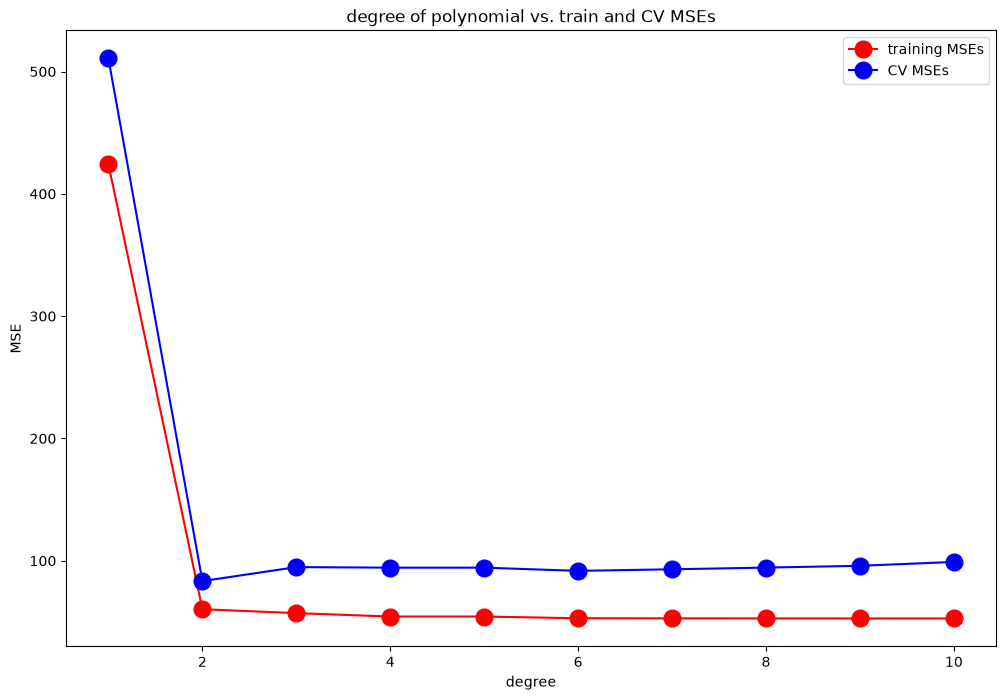

In [23]:
train_mses, cv_mses, models, polys, scalers = model_sel_pipeline(x_train, y_train, x_cv, y_cv, n_deg=10)
degrees = list(range(1, 11))
utils.plot_train_cv_mses(degrees, train_mses, cv_mses, title="degree of polynomial vs. train and CV MSEs")

### Choosing the best model

When selecting a model, you want to choose one that performs well both on the training and cross validation set. It implies that it is able to learn the patterns from your training set without overfitting. If you used the defaults in this lab, you will notice a sharp drop in cross validation error from the models with degree=1 to degree=2. This is followed by a relatively flat line up to degree=5. After that, however, the cross validation error is generally getting worse as you add more polynomial features. Given these, you can decide to use the model with the lowest `cv_mse` as the one best suited for your application.

In [25]:
# Get the model with the lowest CV MSE (add 1 because list indices start at 0)
# Notice the index starts at 0 (degree = 1), so we need to add 1 to get the degree of the polynomial
best_degree = np.argmin(cv_mses) + 1
print(f"Lowest CV MSE is found in the model with degree = {best_degree}")

Lowest CV MSE is found in the model with degree = 2


You can then publish the generalization error by computing the test set's MSE. As usual, you should transform this data the same way you did with the training and cross validation sets.

In [26]:
# Add polynomial features to the test set
X_test_mapped = polys[best_degree-1].transform(x_test)

# Scale the test set
X_test_mapped_scaled = scalers[best_degree-1].transform(X_test_mapped)

# Compute the test MSE
yhat = models[best_degree-1].predict(X_test_mapped_scaled)
test_mse = mean_squared_error(y_test, yhat) / 2

print(f"Training MSE: {train_mses[best_degree-1]:.2f}")
print(f"Cross Validation MSE: {cv_mses[best_degree-1]:.2f}")
print(f"Test MSE: {test_mse:.2f}")

Training MSE: 60.36
Cross Validation MSE: 83.35
Test MSE: 53.00


## Neural Networks

The same model selection process can also be used when choosing between different neural network architectures. In this section, you will create the models shown below and apply it to the same regression task above.

<img src='images/NN_Arch.png' width=40%>

### Prepare the Data

You will use the same training, cross validation, and test sets you generated in the previous section. The default `degree` is set to `1` to indicate that it will just use `x_train`, `x_cv`, and `x_test` as is (i.e. without any additional polynomial features).

In [27]:
# Add polynomial features
degree = 1
poly = PolynomialFeatures(degree, include_bias=False)
X_train_mapped = poly.fit_transform(x_train)
X_cv_mapped = poly.transform(x_cv)
X_test_mapped = poly.transform(x_test)

Next, you will scale the input features to help gradient descent converge faster. Again, notice that you are using the mean and standard deviation computed from the training set by just using `transform()` in the cross validation and test sets instead of `fit_transform()`.

In [28]:
# Scale the features using the zscore
scaler = StandardScaler()
X_train_mapped_scaled = scaler.fit_transform(X_train_mapped)
X_cv_mapped_scaled = scaler.transform(X_cv_mapped)
X_test_mapped = scaler.transform(X_test_mapped)


### Build and train the models

You will then create the neural network architectures shown earlier. The code is provided in the `build_models()` function in the `utils.py` file in case you want to inspect or modify it. You will use that in the loop below then proceed to train the models. For each model, you will also record the training and cross validation errors.

In [30]:
def nn_model_sel(X_train, X_cv, y_train, y_cv):
    nn_train_mses = []
    nn_cv_mses = []

    # Build the nn models
    nn_models = utils.build_models()

    # Loop over the nn models
    for model in nn_models:

        # Setup the loss and optimizer
        model.compile(
            loss = 'mse',
            optimizer = tf.keras.optimizers.Adam(learning_rate=0.1)
        )

        print(f"Training {model.name}...")

        # Train the model
        model.fit(
            X_train, y_train,
            epochs=300,
            verbose=0
        )

        print("Done!\n")

            # Record the training MSEs
        yhat = model.predict(X_train)
        train_mse = mean_squared_error(y_train, yhat) / 2
        nn_train_mses.append(train_mse)
        
        # Record the cross validation MSEs 
        yhat = model.predict(X_cv)
        cv_mse = mean_squared_error(y_cv, yhat) / 2
        nn_cv_mses.append(cv_mse)

    return nn_train_mses, nn_cv_mses

In [31]:
nn_train_mses, nn_cv_mses = nn_model_sel(X_train_mapped_scaled, X_cv_mapped_scaled, y_train, y_cv)

# print results
print("RESULTS:")
for model_num in range(len(nn_train_mses)):
    print(
        f"Model {model_num+1}: Training MSE: {nn_train_mses[model_num]:.2f}, " +
        f"CV MSE: {nn_cv_mses[model_num]:.2f}"
        )

W0000 00:00:1794615497.329490  195589 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Training model_1...
Done!

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
Training model_2...
Done!

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step
Training model_3...
Done!

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
RESULTS:
Model 1: Training MSE: 71.20, CV MSE: 104.32
Model 2: Training MSE: 64.73, CV MSE: 100.30
Model 3: Training MSE: 424.25, CV MSE: 510.67
